In [83]:
print("radha")

radha


In [84]:
import os
from dotenv import load_dotenv
from langchain_groq import ChatGroq
from langgraph.graph import StateGraph,START,END
from typing import TypedDict,Literal
from pydantic import BaseModel,Field
load_dotenv()
groq_api_key = os.getenv("GROQ_API_KEY")
llm = ChatGroq(
    model="openai/gpt-oss-20b",
    groq_api_key=groq_api_key,
)

In [85]:
class SentimentSchema(BaseModel):
    sentiment:Literal['positive','negative'] = Field(description="The sentiment of the review")

class DiagnosisSchema(BaseModel):
    issue_type: Literal['UX','Performance','Bug','Support','Other'] = Field(description='The category of issue')
    tone: Literal['angry','frustrated','disappointed','calm'] = Field(description='Emotional tone')
    urgency: Literal['low','medium','high'] = Field(description='Criticality of the issue')

structured_diagnosis_llm=llm.with_structured_output(DiagnosisSchema)

structured_sentiment_llm=llm.with_structured_output(SentimentSchema)


In [86]:
class ReviewState(TypedDict):
    review:str
    sentiment:Literal['positive','negative']
    diagnosis:dict
    response:str

In [87]:
graph=StateGraph(ReviewState)

In [88]:
def get_sentiment(state:ReviewState):
    review=state['review']
    sentiment_prompt=f"Analyze the sentiment of the following review and return either 'positive' or 'negative':\n\n{review}"
    sentiment=structured_sentiment_llm.invoke(sentiment_prompt).sentiment

    return {'sentiment':sentiment}

def get_conditional_edges(state:ReviewState)->Literal['get_positive_response','get_diagnosis']:
    sentiment=state['sentiment']
    if sentiment=='positive':
        return 'get_positive_response'
    else:
        return 'get_diagnosis'

def get_positive_response(state: ReviewState):
    prompt = f"""
Write a warm thank you message in response to this review:{state['review']}
Also kindly ask the user to leave feedback on our website.
"""
    response = llm.invoke(prompt).content
    return {"response": response}

def get_diagnosis(state: ReviewState):
    prompt = f"""
    Diagnose this negative review: {state['review']}
    Return ONLY JSON with issue_type, tone, urgency.
    """

    diagnosis = structured_diagnosis_llm.invoke(prompt)
    return {"diagnosis": diagnosis}

def get_negative_response(state: ReviewState):
    diagnosis=state['diagnosis']
    prompt=prompt = f"""
You are a support assistant.
The user had a '{diagnosis.issue_type}' issue,
sounded '{diagnosis.tone}',
and marked urgency as '{diagnosis.urgency}'.
Write an empathetic resolution message.
"""
    response=llm.invoke(prompt).content
    return {'response':response}
    

In [89]:
graph.add_node("get_sentiment",get_sentiment)
graph.add_node("get_diagnosis",get_diagnosis)
graph.add_node("get_negative_response",get_negative_response)
graph.add_node("get_positive_response",get_positive_response)

graph.add_edge(START,"get_sentiment")
graph.add_conditional_edges("get_sentiment",get_conditional_edges)

graph.add_edge("get_diagnosis","get_negative_response")
graph.add_edge("get_negative_response",END)

graph.add_edge('get_positive_response',END)

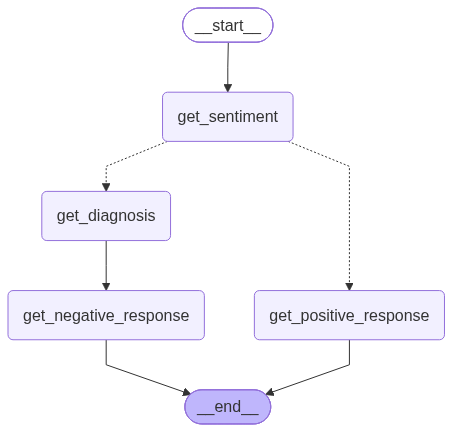

In [90]:
graph.compile()

In [91]:
workflow=graph.compile()

In [92]:
initial_state = {
    "review": "I have been trying to login for an hour now, and the app keeps freezing on the authentication screen. Even tried reinstalling it, but no luck. This kind of bug is not acceptable, especially when it affects basic functionality."
}
final_state = workflow.invoke(initial_state)
print(final_state)

{'review': 'I have been trying to login for an hour now, and the app keeps freezing on the authentication screen. Even tried reinstalling it, but no luck. This kind of bug is not acceptable, especially when it affects basic functionality.', 'sentiment': 'negative', 'diagnosis': DiagnosisSchema(issue_type='Bug', tone='frustrated', urgency='high'), 'response': 'Hi [Customer Name],\n\nThank you for letting us know about the problem you’re experiencing. I’m really sorry that this bug has caused frustration—and I understand how important it is to get things working smoothly, especially when time is tight.\n\nI’m pleased to let you know that our engineering team has identified the root cause and deployed a fix to the live environment. Here’s what you can do next to confirm everything is back on track:\n\n1. **Clear your browser cache** (or restart the app if it’s a mobile/web client).  \n2. **Reload the page / reopen the app** and navigate to the section where the issue was occurring.  \n3. 

In [97]:
from rich.console import Console
from rich.markdown import Markdown
console = Console()
console.print(Markdown(final_state['response']))

Hi [Customer Name],                                                                                                

Thank you for letting us know about the problem you’re experiencing. I’m really sorry that this bug has caused     
frustration—and I understand how important it is to get things working smoothly, especially when time is tight.    

I’m pleased to let you know that our engineering team has identified the root cause and deployed a fix to the live 
environment. Here’s what you can do next to confirm everything is back on track:                                   

 1 Clear your browser cache (or restart the app if it’s a mobile/web client).                                      
 2 Reload the page / reopen the app and navigate to the section where the issue was occurring.                     
 3 Verify that the expected data appears and that no error messages are shown.                                     

If you still see the same problem or encounter any new hiccups, please let me know right away—ideally with a       
screenshot or a short screen recording, and I’ll elevate it to our priority queue.                                 

Again, I apologize for the inconvenience and appreciate your patience while we resolved this. We’re committed to   
keeping your experience seamless, so feel free to reach out anytime you need help.                                 

Thanks for working with us!                                                                                        

Best regards,                                                                                                      
[Your Name]                                                                                                        
Support Team                                                                                                       
[Company] | [Phone] | [Email]